# Steel Industry Data — Assess · Clean · EDA

---
## 1. Load Data

In [1]:
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
%matplotlib inline

zip_path = r'C:/Users/mar-w/OneDrive/Desktop/Steel_industry_data.csv.zip'
with zipfile.ZipFile(zip_path, 'r') as z:
    with z.open(z.namelist()[0]) as f:
        df = pd.read_csv(f)

print('Dataset loaded successfully.')

Dataset loaded successfully.


---
## 2. View Data Visually

In [2]:
# First 5 rows
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


In [3]:
# Last 5 rows
df.tail()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
35035,31/12/2018 23:00,3.85,4.86,0.00,0.0,62.10,100.00,82800,Weekday,Monday,Light_Load
35036,31/12/2018 23:15,3.74,3.74,0.00,0.0,70.71,100.00,83700,Weekday,Monday,Light_Load
35037,31/12/2018 23:30,3.78,3.17,0.07,0.0,76.62,99.98,84600,Weekday,Monday,Light_Load
35038,31/12/2018 23:45,3.78,3.06,0.11,0.0,77.72,99.96,85500,Weekday,Monday,Light_Load
35039,31/12/2018 00:00,3.67,3.02,0.07,0.0,77.22,99.98,0,Weekday,Monday,Light_Load


In [4]:
# Random 5 rows
df.sample(5)

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
14930,05/06/2018 12:45,4.93,0.00,24.84,0.0,100.00,19.47,45900,Weekday,Tuesday,Medium_Load
20441,01/08/2018 22:30,3.24,4.93,0.00,0.0,54.92,100.00,81000,Weekday,Wednesday,Light_Load
6905,13/03/2018 22:30,3.89,5.00,0.00,0.0,61.40,100.00,81000,Weekday,Tuesday,Medium_Load
25538,24/09/2018 00:45,2.74,5.72,0.00,0.0,43.20,100.00,2700,Weekday,Monday,Light_Load
28425,24/10/2018 02:30,3.78,6.52,0.00,0.0,50.16,100.00,9000,Weekday,Wednesday,Light_Load


---
## 3. Inspect Data Programmatically

In [5]:
print('Shape:', df.shape)

Shape: (35040, 11)


In [6]:
print('Columns:')
print(df.columns.tolist())

Columns:
['date', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']


In [7]:
df.dtypes

date                                     object
Usage_kWh                               float64
Lagging_Current_Reactive.Power_kVarh    float64
Leading_Current_Reactive_Power_kVarh    float64
CO2(tCO2)                               float64
Lagging_Current_Power_Factor            float64
Leading_Current_Power_Factor            float64
NSM                                       int64
WeekStatus                               object
Day_of_week                              object
Load_Type                                object
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  object 
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-null  float64
 7   NSM                                   35040 non-null  int64  
 8   WeekStatus                            35040 non-null  object 
 9   Day_of_week                           35040 non-null  object 
 10  Load_Type                             35040 non-null  object 
dtypes: float64(6), 

In [9]:
# Numeric columns summary
df.describe()

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
count,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000
mean,27.386892,13.035384,3.870949,0.011524,80.578056,84.367870,42750.000000
std,33.444380,16.306000,7.424463,0.016151,18.921322,30.456535,24940.534317
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.200000,2.300000,0.000000,0.000000,63.320000,99.700000,21375.000000
50%,4.570000,5.000000,0.000000,0.000000,87.960000,100.000000,42750.000000
75%,51.237500,22.640000,2.090000,0.020000,99.022500,100.000000,64125.000000
max,157.180000,96.910000,27.760000,0.070000,100.000000,100.000000,85500.000000


In [10]:
# Categorical columns summary
df.describe(include='object')

,date,WeekStatus,Day_of_week,Load_Type
count,35040,35040,35040,35040
unique,35040,2,7,3
top,01/01/2018 00:15,Weekday,Monday,Light_Load
freq,1,25056,5088,18072


In [11]:
# Value counts per categorical column
cat_cols = df.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    print(f'\n"{col}" — {df[col].nunique()} unique values:')
    print(df[col].value_counts())


"date" — 35040 unique values:
date
01/01/2018 00:15    1
01/09/2018 08:45    1
01/09/2018 07:15    1
01/09/2018 07:30    1
01/09/2018 07:45    1
                   ..
02/05/2018 14:45    1
02/05/2018 14:30    1
02/05/2018 14:15    1
02/05/2018 14:00    1
31/12/2018 00:00    1
Name: count, Length: 35040, dtype: int64

"WeekStatus" — 2 unique values:
WeekStatus
Weekday    25056
Weekend     9984
Name: count, dtype: int64

"Day_of_week" — 7 unique values:
Day_of_week
Monday       5088
Tuesday      4992
Wednesday    4992
Thursday     4992
Friday       4992
Saturday     4992
Sunday       4992
Name: count, dtype: int64

"Load_Type" — 3 unique values:
Load_Type
Light_Load      18072
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64


---
## 4. Identify Quality Issues

In [12]:
# QI-1: Missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
result = pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct})
result = result[result['missing_count'] > 0]

if result.empty:
    print('No missing values found.')
else:
    print('ISSUE — Missing values:')
    print(result)

No missing values found.


In [13]:
# QI-2: Duplicate rows
dups = df.duplicated().sum()
if dups > 0:
    print(f'ISSUE — {dups} duplicate rows found.')
    print(df[df.duplicated(keep=False)].head(6))
else:
    print('No duplicate rows.')

No duplicate rows.


In [14]:
# QI-3: Wrong data types — date stored as string
date_cols = [c for c in df.columns if 'date' in c.lower() or 'time' in c.lower()]
for col in date_cols:
    if df[col].dtype == object:
        print(f'ISSUE — "{col}" is dtype object (string), should be datetime.')
        print(f'  Sample values: {df[col].head(3).tolist()}')
    else:
        print(f'"{col}" dtype is already {df[col].dtype}.')

ISSUE — "date" is dtype object (string), should be datetime.
  Sample values: ['01/01/2018 00:15', '01/01/2018 00:30', '01/01/2018 00:45']


In [15]:
# QI-4: Inconsistent formats — whitespace & mixed case in categorical columns
cat_cols = df.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    has_whitespace = not (df[col].str.strip() == df[col]).all()
    has_mixed_case = df[col].str.lower().nunique() < df[col].nunique()
    if has_whitespace:
        print(f'ISSUE — "{col}": leading/trailing whitespace found.')
    if has_mixed_case:
        print(f'ISSUE — "{col}": mixed-case entries.')
    if not has_whitespace and not has_mixed_case:
        print(f'"{col}": consistent format.')

"date": consistent format.
"WeekStatus": consistent format.
"Day_of_week": consistent format.
"Load_Type": consistent format.


In [16]:
# QI-5: Invalid / unrealistic values
numeric_cols = df.select_dtypes(include='number').columns.tolist()
issues = []

non_neg_cols = [c for c in numeric_cols if any(k in c.lower() for k in ['kwh', 'kvar', 'co2'])]
for col in non_neg_cols:
    n = (df[col] < 0).sum()
    if n: issues.append(f'ISSUE — "{col}": {n} negative values (must be >= 0)')

pf_cols = [c for c in numeric_cols if 'factor' in c.lower()]
for col in pf_cols:
    n = ((df[col] < 0) | (df[col] > 100)).sum()
    if n: issues.append(f'ISSUE — "{col}": {n} values outside [0, 100]')

if 'NSM' in df.columns:
    n = ((df['NSM'] < 0) | (df['NSM'] > 86399)).sum()
    if n: issues.append(f'ISSUE — "NSM": {n} values outside [0, 86399]')

print('\n'.join(issues) if issues else 'No impossible values found.')
print()

# Outliers via IQR
rows = []
for col in numeric_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    if n > 0:
        rows.append({'column': col, 'outliers': n, '%': round(n/len(df)*100, 2),
                     'IQR_lower': round(lo, 3), 'IQR_upper': round(hi, 3),
                     'actual_min': round(df[col].min(), 3), 'actual_max': round(df[col].max(), 3)})
if rows:
    print('ISSUE — Outliers (IQR method):')
    print(pd.DataFrame(rows).to_string(index=False))
else:
    print('No outliers detected.')

No impossible values found.

ISSUE — Outliers (IQR method):
                              column  outliers     %  IQR_lower  IQR_upper  actual_min  actual_max
                           Usage_kWh       328  0.94    -68.856    123.294         0.0      157.18
Lagging_Current_Reactive.Power_kVarh      1059  3.02    -28.210     53.150         0.0       96.91
Leading_Current_Reactive_Power_kVarh      7759 22.14     -3.135      5.225         0.0       27.76
                           CO2(tCO2)       437  1.25     -0.030      0.050         0.0        0.07
        Lagging_Current_Power_Factor         1  0.00      9.766    152.576         0.0      100.00
        Leading_Current_Power_Factor      8327 23.76     99.250    100.450         0.0      100.00


---
## 5. Identify Tidiness Issues

In [17]:
# TI-1: Multiple variables in one column (date + time combined)
date_cols = [c for c in df.columns if 'date' in c.lower() or 'time' in c.lower()]
for col in date_cols:
    sample = df[col].iloc[0]
    has_time = ' ' in str(sample) or 'T' in str(sample)
    if has_time:
        print(f'ISSUE — "{col}": contains both date and time in one column.')
        print(f'  Sample: {sample}')
    else:
        print(f'"{col}": date only (no time component detected).')

ISSUE — "date": contains both date and time in one column.
  Sample: 01/01/2018 00:15


In [18]:
# TI-2: Redundant / derivable columns
redundant = []
has_date = any('date' in c.lower() for c in df.columns)
if 'NSM' in df.columns and has_date:
    redundant.append(('NSM', 'derivable from date (seconds since midnight)'))
if 'Day_of_week' in df.columns and has_date:
    redundant.append(('Day_of_week', 'derivable from date (.dt.day_name())'))
if 'WeekStatus' in df.columns and 'Day_of_week' in df.columns:
    redundant.append(('WeekStatus', 'derivable from Day_of_week'))

if redundant:
    print('ISSUE — Redundant columns:')
    for col, reason in redundant:
        print(f'  "{col}": {reason}')
else:
    print('No redundant columns.')

ISSUE — Redundant columns:
  "NSM": derivable from date (seconds since midnight)
  "Day_of_week": derivable from date (.dt.day_name())
  "WeekStatus": derivable from Day_of_week


In [19]:
# TI-3: Column naming issues (dots, whitespace)
found = False
for col in df.columns:
    if '.' in col:
        print(f'ISSUE — "{col}": dot in name → should use underscore')
        found = True
    if col != col.strip():
        print(f'ISSUE — "{col}": leading/trailing whitespace in column name')
        found = True
if not found:
    print('No column naming issues.')

ISSUE — "Lagging_Current_Reactive.Power_kVarh": dot in name → should use underscore


In [20]:
# TI-4: Duplicate timestamps & time gaps (observations spread across rows / missing rows)
date_col_name = [c for c in df.columns if 'date' in c.lower() or 'time' in c.lower()]
if date_col_name:
    col = date_col_name[0]
    tmp = pd.to_datetime(df[col], dayfirst=True, errors='coerce')
    dup_ts = tmp.duplicated().sum()
    print(f'Duplicate timestamps: {dup_ts}')
    if dup_ts > 0:
        print('ISSUE — Same moment recorded in multiple rows.')

    tmp_sorted = tmp.sort_values()
    diffs = tmp_sorted.diff().dropna()
    freq = diffs.mode()[0]
    gaps = diffs[diffs > freq]
    print(f'Expected interval : {freq}')
    print(f'Time gaps detected: {len(gaps)}')
    if not gaps.empty:
        print('ISSUE — Missing time intervals:')
        print(tmp_sorted[gaps.index].values)

Duplicate timestamps: 0
Expected interval : 0 days 00:15:00
Time gaps detected: 0


In [21]:
# TI-5: Highly correlated columns (r > 0.95) — potential redundant features
num_df = df.select_dtypes(include='number')
corr = num_df.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = [(c, r, round(upper.loc[r, c], 3))
         for c in upper.columns for r in upper.index
         if pd.notna(upper.loc[r, c]) and upper.loc[r, c] > 0.95]

if pairs:
    print('ISSUE — Highly correlated pairs (r > 0.95):')
    for a, b, r in pairs:
        print(f'  {a} <-> {b}: r = {r}')
else:
    print('No highly correlated pairs.')

ISSUE — Highly correlated pairs (r > 0.95):
  CO2(tCO2) <-> Usage_kWh: r = 0.988


---
## 6. Document Findings

### Quality Issues

| # | Issue | Column(s) | Details |
|---|-------|-----------|----------|
| QI-1 | Missing values | — | Run cell to confirm |
| QI-2 | Duplicate rows | — | 0 duplicates confirmed |
| QI-3 | Wrong data type | `date` | Stored as string, should be datetime |
| QI-4 | Inconsistent format | categorical cols | Check for whitespace / mixed case |
| QI-5 | Invalid / outlier values | numeric cols | Outliers detected via IQR — cap required |

### Tidiness Issues

| # | Issue | Column(s) | Details |
|---|-------|-----------|----------|
| TI-1 | Multiple variables in one column | `date` | Date + time combined in single string field |
| TI-2 | Redundant derivable columns | `NSM`, `Day_of_week`, `WeekStatus` | All derivable from `date` |
| TI-3 | Column naming | cols with `.` | Dots break `df.col` attribute access |
| TI-4 | Missing time observations | `date` | Gaps in time series continuity |
| TI-5 | Highly correlated features | numeric cols | Redundant information if r > 0.95 |

---
## 7. Clean Data
### 7.1 Reload fresh copy

In [22]:
with zipfile.ZipFile(zip_path, 'r') as z:
    with z.open(z.namelist()[0]) as f:
        df_clean = pd.read_csv(f)

print(f'Original shape: {df_clean.shape}')

Original shape: (35040, 11)


### 7.2 Fix column names — strip whitespace & replace dots

In [23]:
df_clean.columns = df_clean.columns.str.strip().str.replace('.', '_', regex=False)
print('Columns after rename:')
print(df_clean.columns.tolist())

Columns after rename:
['date', 'Usage_kWh', 'Lagging_Current_Reactive_Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']


### 7.3 Parse date column to datetime & sort chronologically

In [24]:
date_col = [c for c in df_clean.columns if 'date' in c.lower() or 'time' in c.lower()][0]
df_clean[date_col] = pd.to_datetime(df_clean[date_col], dayfirst=True, errors='coerce')
df_clean = df_clean.sort_values(date_col).reset_index(drop=True)

print(f'Date column : "{date_col}" → dtype: {df_clean[date_col].dtype}')
print(f'Range       : {df_clean[date_col].min()} → {df_clean[date_col].max()}')
print(f'Unparseable : {df_clean[date_col].isnull().sum()}')

Date column : "date" → dtype: datetime64[ns]
Range       : 2018-01-01 00:00:00 → 2018-12-31 23:45:00
Unparseable : 0


### 7.4 Remove duplicate timestamps (keep first)

In [25]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=[date_col], keep='first').reset_index(drop=True)
print(f'Duplicate timestamps removed: {before - len(df_clean)} | Shape: {df_clean.shape}')

Duplicate timestamps removed: 0 | Shape: (35040, 11)


### 7.5 Handle missing values

In [26]:
numeric_cols = df_clean.select_dtypes(include='number').columns.tolist()
cat_cols     = df_clean.select_dtypes(include='object').columns.tolist()

# Numeric: linear interpolation (time-series aware)
df_clean[numeric_cols] = df_clean[numeric_cols].interpolate(method='linear', limit_direction='both')

# Categorical: forward fill then backward fill
df_clean[cat_cols] = df_clean[cat_cols].ffill().bfill()

print(f'Missing values remaining: {df_clean.isnull().sum().sum()}')

Missing values remaining: 0


### 7.6 Strip whitespace from categorical values

In [27]:
cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    df_clean[col] = df_clean[col].str.strip()
    print(f'"{col}": {sorted(df_clean[col].unique().tolist())}')

"WeekStatus": ['Weekday', 'Weekend']
"Day_of_week": ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
"Load_Type": ['Light_Load', 'Maximum_Load', 'Medium_Load']


### 7.7 Cap outliers (IQR Winsorization)

In [28]:
numeric_cols = df_clean.select_dtypes(include='number').columns.tolist()
for col in numeric_cols:
    Q1, Q3 = df_clean[col].quantile(0.25), df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
    if n > 0:
        df_clean[col] = df_clean[col].clip(lower=lo, upper=hi)
        print(f'  {col}: {n} values capped to [{round(lo,3)}, {round(hi,3)}]')

print('Outlier capping done.')

  Usage_kWh: 328 values capped to [-68.856, 123.294]
  Lagging_Current_Reactive_Power_kVarh: 1059 values capped to [-28.21, 53.15]
  Leading_Current_Reactive_Power_kVarh: 7759 values capped to [-3.135, 5.225]
  CO2(tCO2): 437 values capped to [-0.03, 0.05]
  Lagging_Current_Power_Factor: 1 values capped to [9.766, 152.576]
  Leading_Current_Power_Factor: 8327 values capped to [99.25, 100.45]
Outlier capping done.


### 7.8 Convert string columns to category dtype

In [29]:
cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    df_clean[col] = df_clean[col].astype('category')
    print(f'"{col}" → category: {df_clean[col].cat.categories.tolist()}')

"WeekStatus" → category: ['Weekday', 'Weekend']
"Day_of_week" → category: ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
"Load_Type" → category: ['Light_Load', 'Maximum_Load', 'Medium_Load']


### 7.9 Re-derive NSM, Day_of_week, WeekStatus from date

In [30]:
if 'NSM' in df_clean.columns:
    df_clean['NSM'] = (df_clean[date_col].dt.hour * 3600
                       + df_clean[date_col].dt.minute * 60
                       + df_clean[date_col].dt.second)
    print('NSM re-derived.')

if 'Day_of_week' in df_clean.columns:
    df_clean['Day_of_week'] = df_clean[date_col].dt.day_name().astype('category')
    print('Day_of_week re-derived.')

if 'WeekStatus' in df_clean.columns:
    df_clean['WeekStatus'] = df_clean[date_col].dt.dayofweek.apply(
        lambda x: 'Weekend' if x >= 5 else 'Weekday'
    ).astype('category')
    print('WeekStatus re-derived.')

NSM re-derived.
Day_of_week re-derived.
WeekStatus re-derived.


### 7.10 Final check

In [31]:
print('=== CLEANED DATASET ===')
print(f'Shape        : {df_clean.shape}')
print(f'Missing vals : {df_clean.isnull().sum().sum()}')
print(f'Duplicates   : {df_clean.duplicated().sum()}')
print()
df_clean.head(3)

=== CLEANED DATASET ===
Shape        : (35040, 11)
Missing vals : 0
Duplicates   : 0



,date,Usage_kWh,Lagging_Current_Reactive_Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,2018-01-01 00:00:00,3.42,3.46,0.0,0.0,70.30,100.0,0,Weekday,Monday,Light_Load
1,2018-01-01 00:15:00,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
2,2018-01-01 00:30:00,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load


---
## 8. Exploratory Data Analysis (EDA)
### 8.1 Distribution of numeric columns

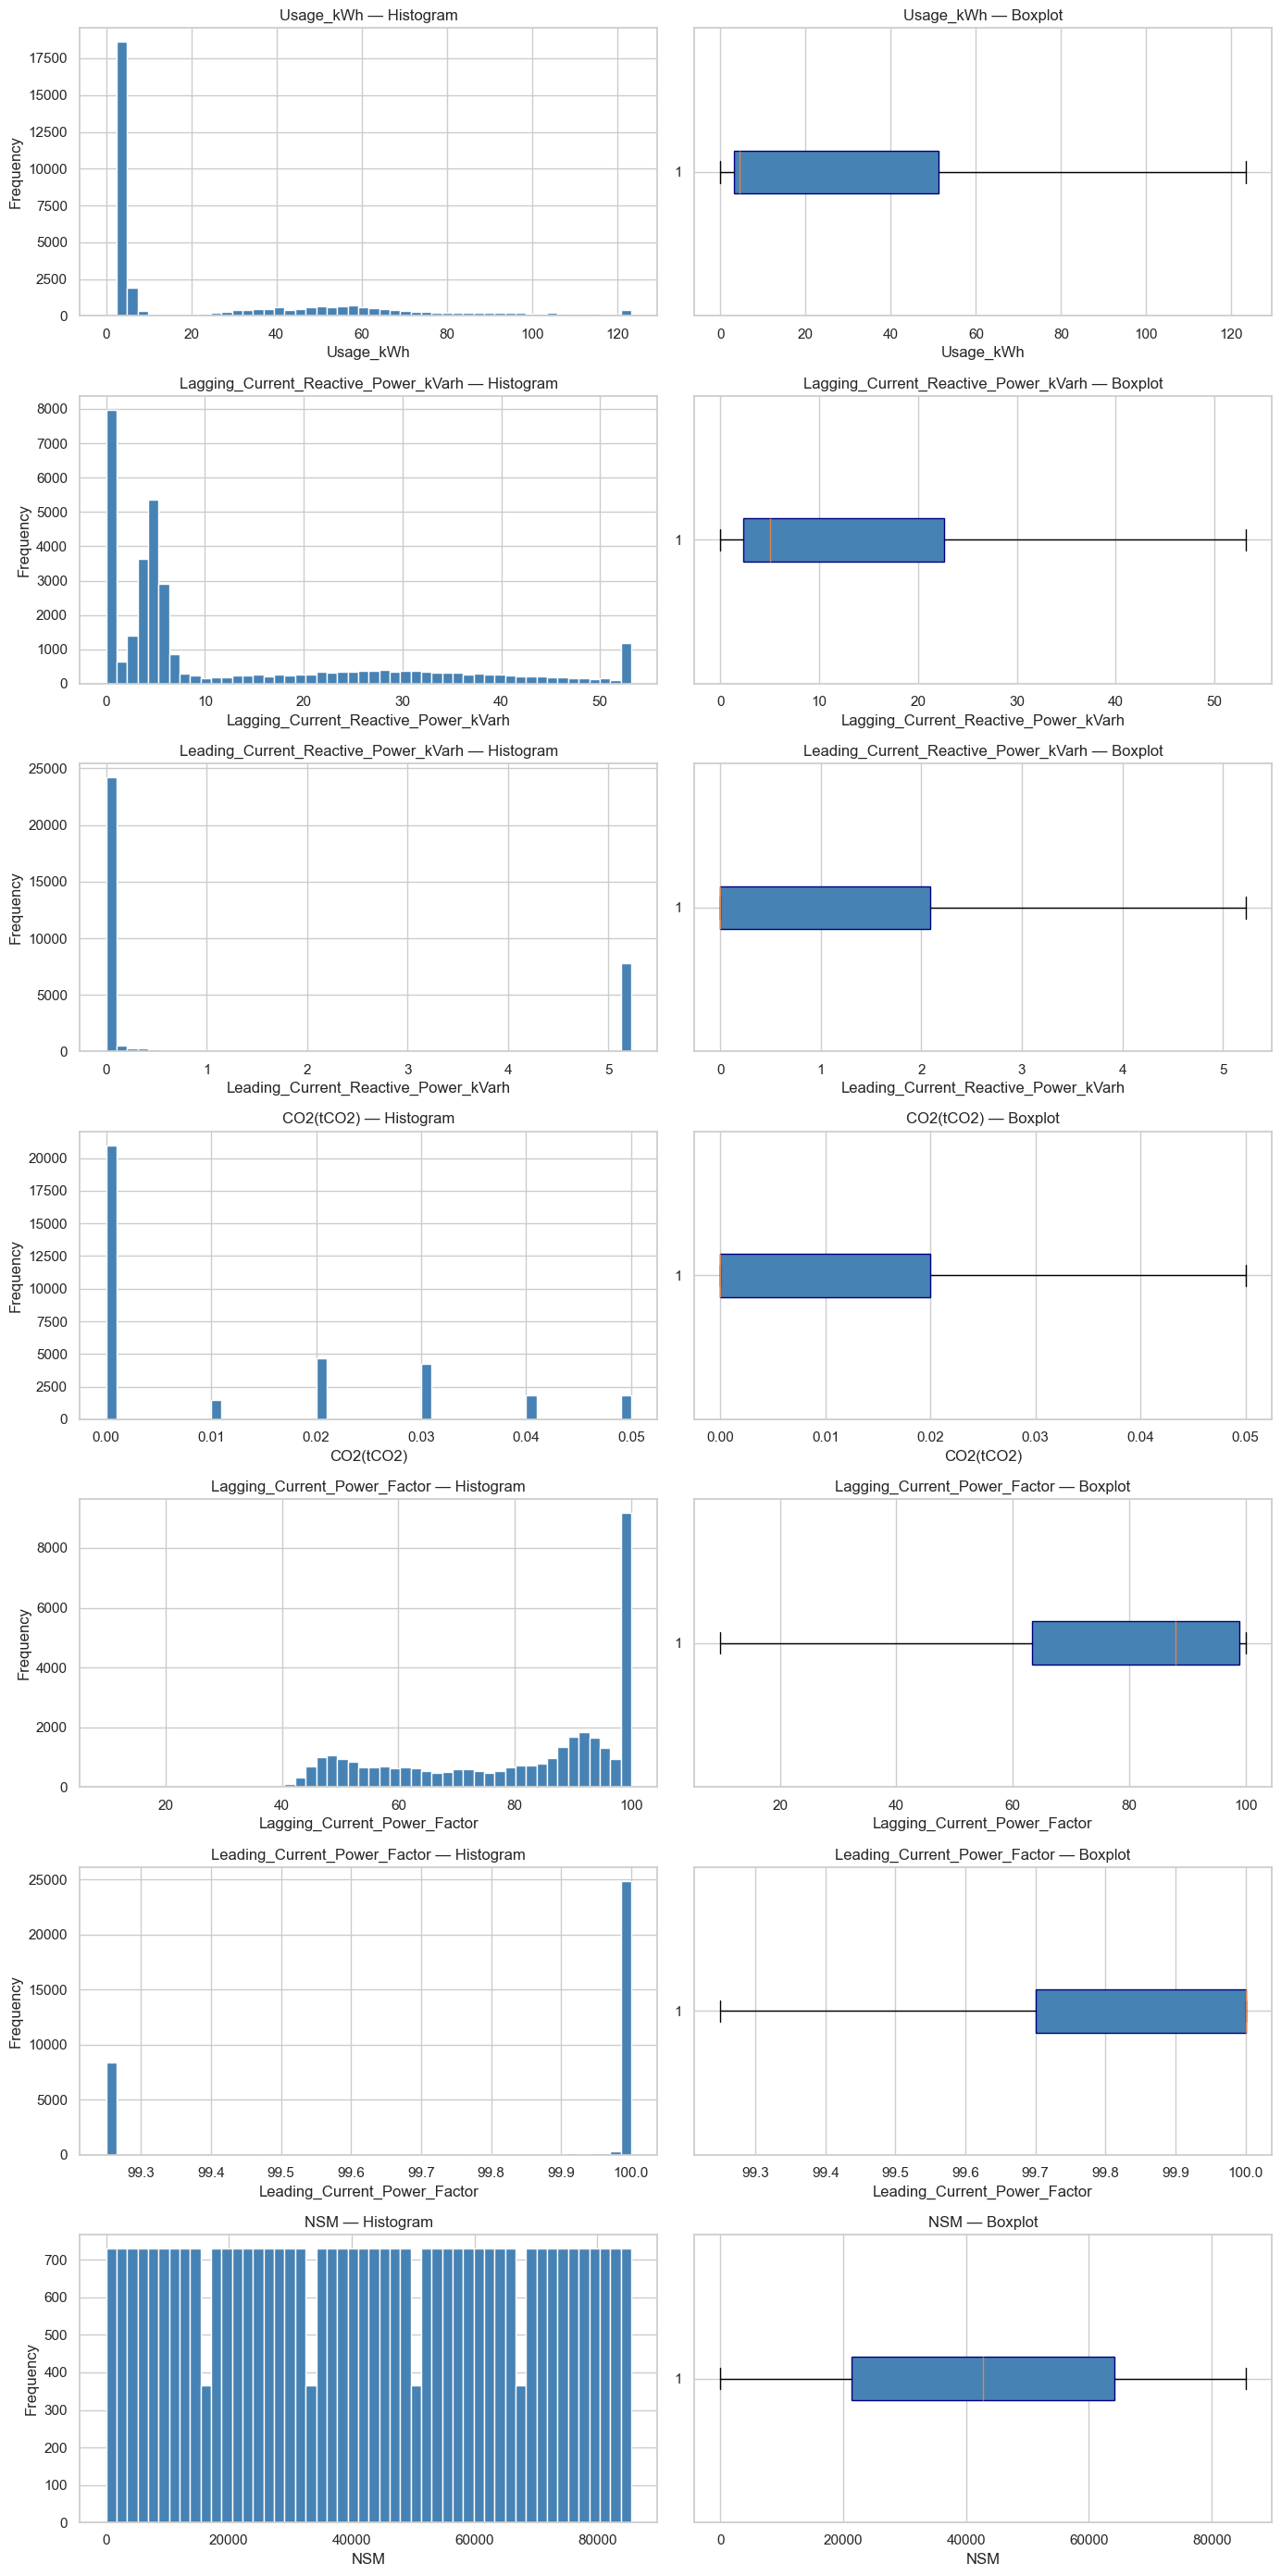

In [32]:
numeric_cols = df_clean.select_dtypes(include='number').columns.tolist()

fig, axes = plt.subplots(nrows=len(numeric_cols), ncols=2, figsize=(14, 4*len(numeric_cols)))

for i, col in enumerate(numeric_cols):
    # Histogram
    axes[i, 0].hist(df_clean[col].dropna(), bins=50, color='steelblue', edgecolor='white')
    axes[i, 0].set_title(f'{col} — Histogram')
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel('Frequency')

    # Boxplot
    axes[i, 1].boxplot(df_clean[col].dropna(), vert=False, patch_artist=True,
                       boxprops=dict(facecolor='steelblue', color='navy'))
    axes[i, 1].set_title(f'{col} — Boxplot')
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

### 8.2 Distribution of categorical columns

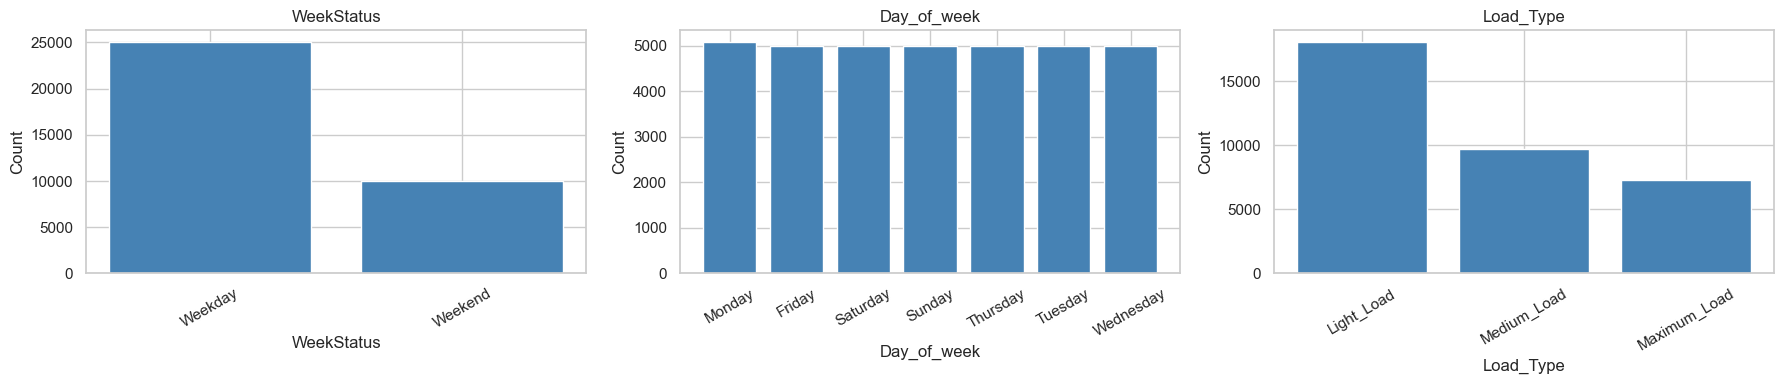

In [33]:
cat_cols = df_clean.select_dtypes(include='category').columns.tolist()

fig, axes = plt.subplots(1, len(cat_cols), figsize=(6 * len(cat_cols), 4))
if len(cat_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, cat_cols):
    counts = df_clean[col].value_counts()
    ax.bar(counts.index.astype(str), counts.values, color='steelblue', edgecolor='white')
    ax.set_title(f'{col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### 8.3 Energy consumption over time

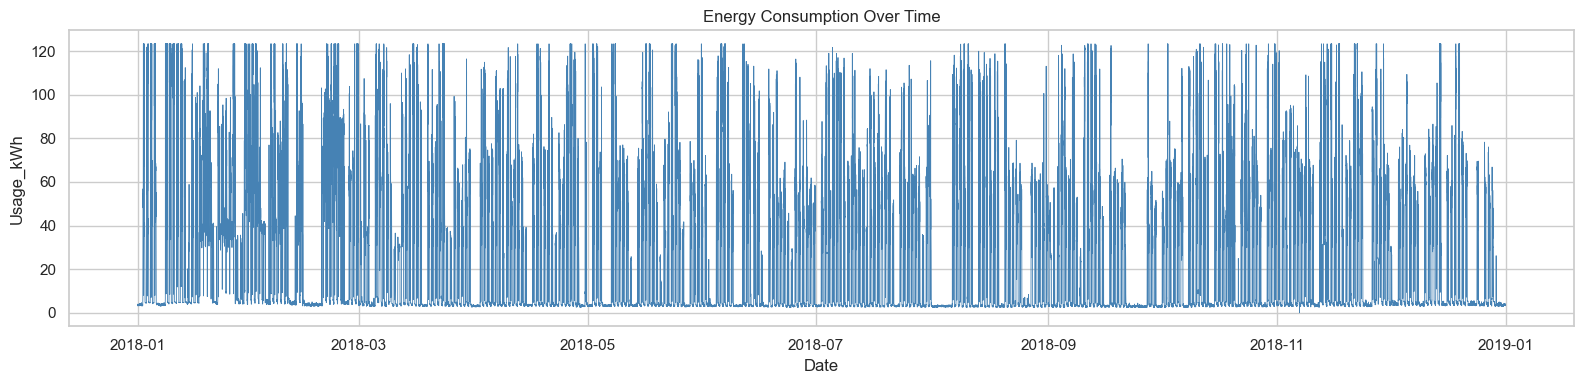

In [34]:
usage_col = [c for c in df_clean.columns if 'kwh' in c.lower()][0]

plt.figure(figsize=(16, 4))
plt.plot(df_clean[date_col], df_clean[usage_col], linewidth=0.6, color='steelblue')
plt.title('Energy Consumption Over Time')
plt.xlabel('Date')
plt.ylabel(usage_col)
plt.tight_layout()
plt.show()

### 8.4 Average energy consumption by Load Type

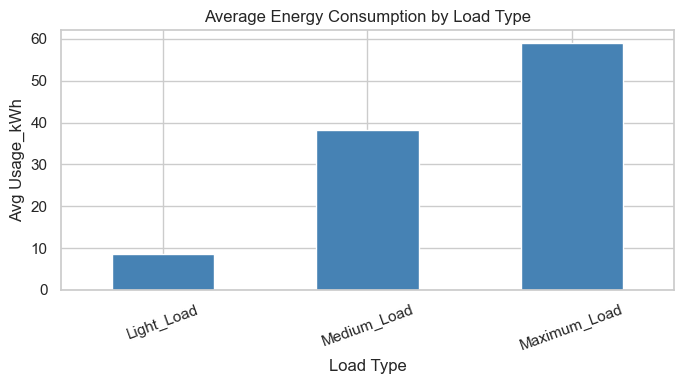

In [35]:
if 'Load_Type' in df_clean.columns:
    avg = df_clean.groupby('Load_Type', observed=True)[usage_col].mean().sort_values()
    avg.plot(kind='bar', color='steelblue', edgecolor='white', figsize=(7, 4))
    plt.title('Average Energy Consumption by Load Type')
    plt.xlabel('Load Type')
    plt.ylabel(f'Avg {usage_col}')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

### 8.5 Average energy consumption by Day of Week

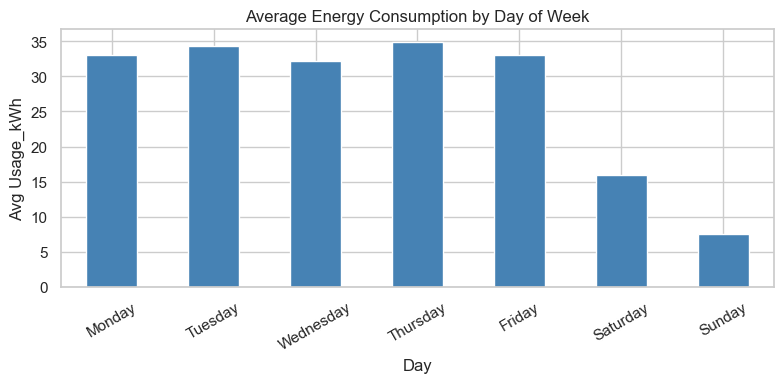

In [36]:
if 'Day_of_week' in df_clean.columns:
    day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
    avg_day = df_clean.groupby('Day_of_week', observed=True)[usage_col].mean().reindex(day_order)
    avg_day.plot(kind='bar', color='steelblue', edgecolor='white', figsize=(8, 4))
    plt.title('Average Energy Consumption by Day of Week')
    plt.xlabel('Day')
    plt.ylabel(f'Avg {usage_col}')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

### 8.6 Weekday vs Weekend energy consumption

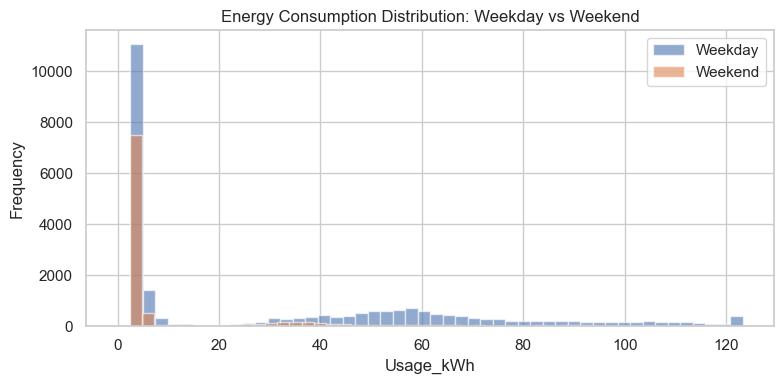

In [37]:
if 'WeekStatus' in df_clean.columns:
    df_clean.groupby('WeekStatus', observed=True)[usage_col].plot(
        kind='hist', bins=50, alpha=0.6, figsize=(8, 4), legend=True
    )
    plt.title('Energy Consumption Distribution: Weekday vs Weekend')
    plt.xlabel(usage_col)
    plt.tight_layout()
    plt.show()

### 8.7 Correlation heatmap

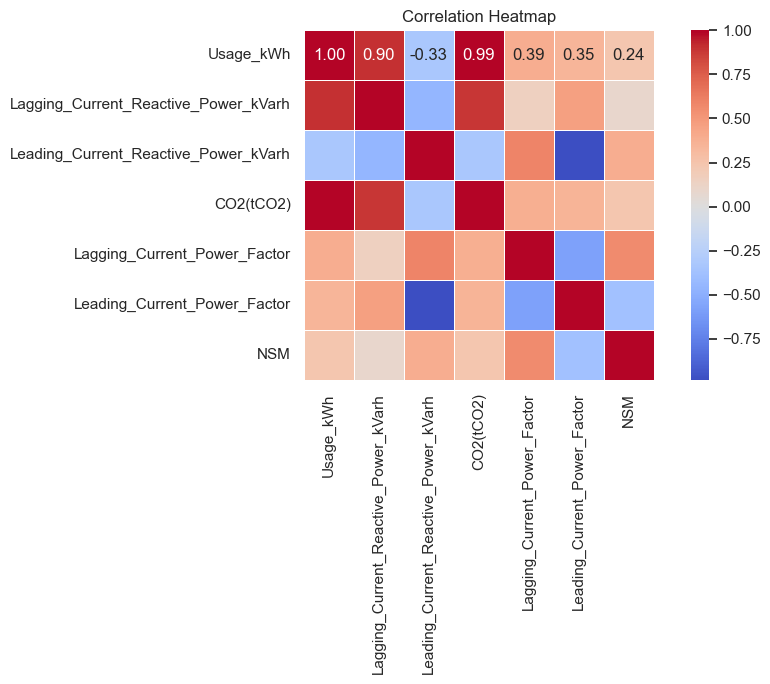

In [38]:
numeric_cols = df_clean.select_dtypes(include='number').columns.tolist()
corr_matrix = df_clean[numeric_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, square=True)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### 8.8 Monthly average energy consumption

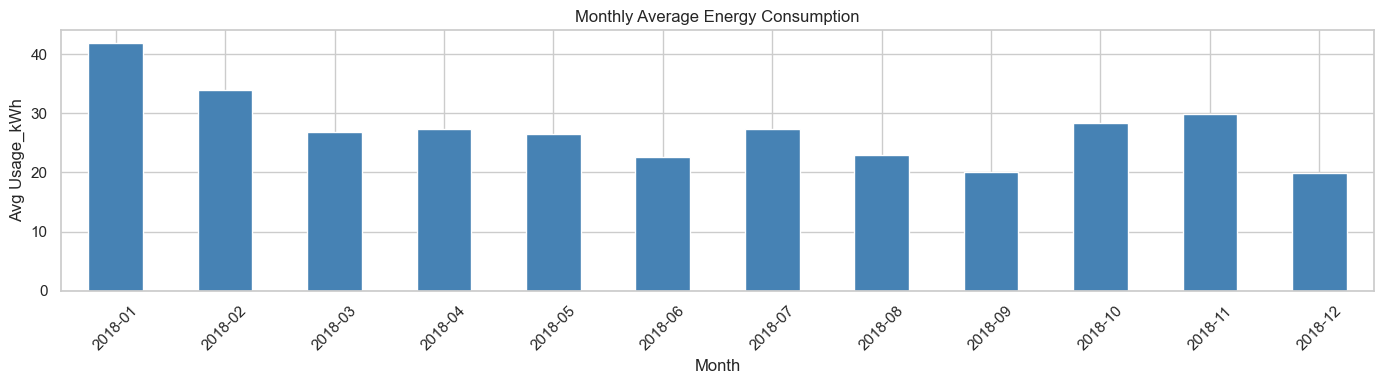

In [39]:
df_clean['month'] = df_clean[date_col].dt.to_period('M')
monthly = df_clean.groupby('month')[usage_col].mean()

plt.figure(figsize=(14, 4))
monthly.plot(kind='bar', color='steelblue', edgecolor='white')
plt.title('Monthly Average Energy Consumption')
plt.xlabel('Month')
plt.ylabel(f'Avg {usage_col}')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

df_clean.drop(columns=['month'], inplace=True)

### 8.9 Hourly average energy consumption

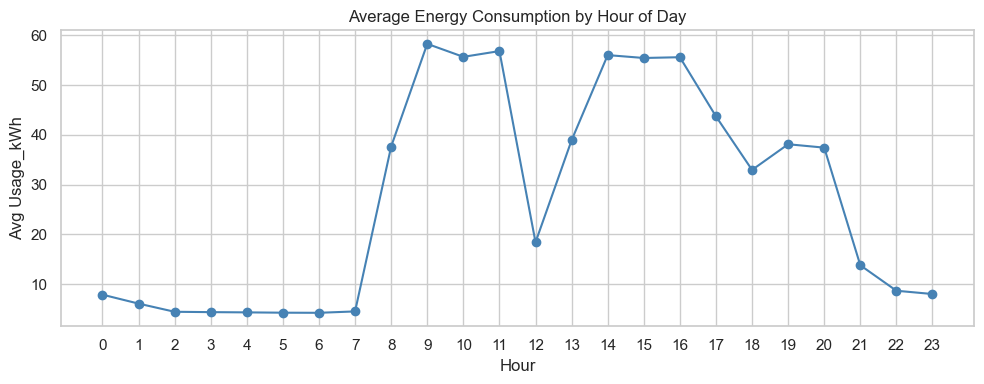

In [40]:
df_clean['hour'] = df_clean[date_col].dt.hour
hourly = df_clean.groupby('hour')[usage_col].mean()

plt.figure(figsize=(10, 4))
hourly.plot(kind='line', marker='o', color='steelblue')
plt.title('Average Energy Consumption by Hour of Day')
plt.xlabel('Hour')
plt.ylabel(f'Avg {usage_col}')
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

df_clean.drop(columns=['hour'], inplace=True)

---
## 9. Save Cleaned Dataset

In [ ]:
output_path = r'C:/Users/mar-w/OneDrive/Desktop/Steel_industry_data_cleaned.csv'
df_clean.to_csv(output_path, index=False)
print(f'Saved: {output_path}')

Saved: C:/Users/mar-w/OneDrive/Desktop/Steel_industry_data_cleaned.csv


: 